# ENGG2112: ResNet-18, Random Forest, and CNN-BiLSTM comparison

This notebook **compares saved validation results only**; it does not train or evaluate models. It reads the fine-tuned ResNet-18 result and the independent Random Forest and CNN-BiLSTM results. It checks that all three recorded the same current split-manifest SHA-256 and validation sample count before showing a comparison.

The RF and CNN-BiLSTM use a frozen ImageNet ResNet-18 feature extractor; the ResNet baseline fine-tunes its backbone. Thus this comparison is between three model pipelines, not a fully controlled architecture-only ablation. RF and CNN-BiLSTM results summarize three seeds; ResNet-18 is the saved single-seed run. The existing split remains provisional and test evaluation is intentionally excluded.

**Execution provenance (1 November 2026):** saved outputs below are retained from the earlier model runs. The path/cache maintenance changes have been checked separately; the models have not been retrained for this maintenance change. These are historical validation results, not final test results. Run all cells in order with your authorised data to generate a new run. See [current status and remaining evaluation work](../docs/PROJECT_STATUS.md).


## Inputs and run order

1. Run [ENGG2112_Model_Training.ipynb](ENGG2112_Model_Training.ipynb) to create the fine-tuned ResNet-18 validation result. The notebook now records the split-manifest fingerprint; rerun it once to refresh its result metadata.
2. Run [ENGG2112_Random_Forest.ipynb](ENGG2112_Random_Forest.ipynb).
3. Run [ENGG2112_CNN_BiLSTM.ipynb](ENGG2112_CNN_BiLSTM.ipynb).
4. Run this notebook. It refuses to compare results unless all have the same manifest fingerprint and validation support.

RF and CNN-BiLSTM each report a three-seed mean and standard deviation; ResNet-18 is a single seeded run. The comparison table makes this difference visible by leaving ResNet's between-seed standard deviation blank.
Open this notebook from the complete repository. Paths are resolved from the repository root, including when the kernel starts inside `jupyter notebooks/`. Edit `PROJECT_ROOT` and `DATA_ROOT` for external data. RF and CNN-BiLSTM use `src/model_support.py` from this checkout.


Common split SHA-256: 81283b51d8274a7d4ee5cd873cfc6479fd9efd178a75bacd45e297dd41d57a54
Validation sample count: 538


,model,validation_n,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,quadratic_weighted_kappa_mean,quadratic_weighted_kappa_std
0,Fine-tuned ResNet-18,538,0.8216,NaN,0.6486,NaN,0.6607,NaN,0.8162,NaN,0.8754,NaN
1,Random Forest,538,0.7683,0.0028,0.4441,0.0067,0.4373,0.0120,0.7219,0.0049,0.7965,0.0041
2,CNN-BiLSTM,538,0.7627,0.0222,0.6547,0.0152,0.6064,0.0185,0.7702,0.0235,0.8187,0.0056


model,CNN-BiLSTM,Fine-tuned ResNet-18,Random Forest
class,,,
Mild,0.741,0.648,0.259
Moderate,0.534,0.777,0.899
No DR,0.959,0.981,0.974
Proliferative DR,0.500,0.375,0.025
Severe,0.615,0.462,0.038


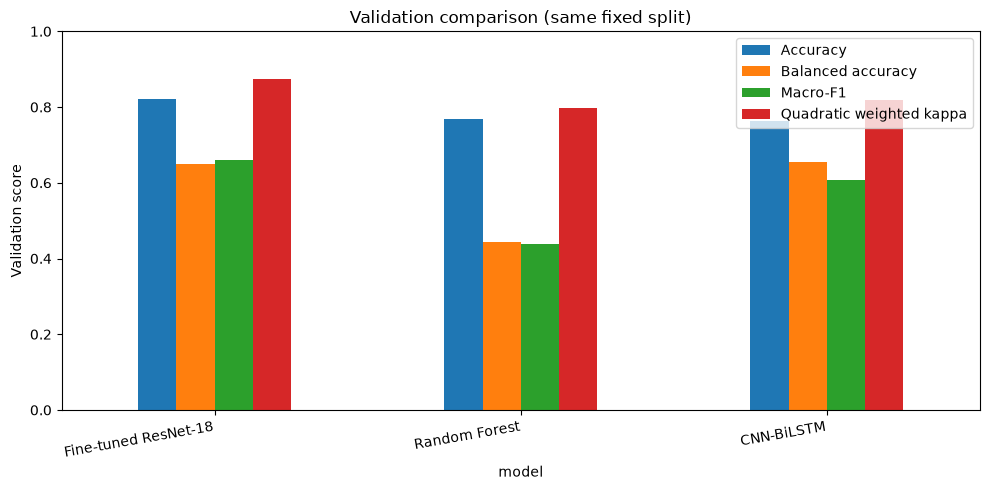

Comparison saved to: /Users/quangduyvu1723/Documents/GitHub/ENGG2112-final-project/outputs/aptos_model_comparison/validation_comparison.json


In [1]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root(start=None):
    """Find the repository or extracted handoff from the kernel's working folder."""
    start = Path.cwd() if start is None else Path(start)
    start = start.resolve()
    for candidate in (start, *start.parents):
        repository = (candidate / 'requirements.txt').is_file() and (candidate / 'src').is_dir()
        handoff = ((candidate / 'data/train.csv').is_file()
                   and (candidate / 'artifacts/splits').is_dir())
        if repository or handoff:
            return candidate
    raise FileNotFoundError(
        'Cannot locate the project. Set PROJECT_ROOT to the absolute repository '
        'or prepared handoff folder in this configuration cell.'
    )

PROJECT_ROOT = find_project_root()  # Or Path(r'/absolute/path/to/project').resolve()

DATA_ROOT = PROJECT_ROOT / 'artifacts/notebook_runs/notebook_run_001'
SPLIT_PATH = DATA_ROOT / 'artifacts/splits/split_manifest.csv'
RESNET_RESULTS_PATH = PROJECT_ROOT / 'outputs/aptos_resnet18_run/validation_metrics.json'
RF_RESULTS_PATH = PROJECT_ROOT / 'outputs/aptos_random_forest/validation_metrics.json'
RNN_RESULTS_PATH = PROJECT_ROOT / 'outputs/aptos_cnn_bilstm/validation_metrics.json'

required_paths = [SPLIT_PATH, RESNET_RESULTS_PATH, RF_RESULTS_PATH, RNN_RESULTS_PATH]
missing = [str(path) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(
        'Run each single-model notebook first (and rerun the ResNet-18 notebook once '
        'to record its split fingerprint). Missing: ' + ', '.join(missing)
    )
current_manifest_hash = hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest()
resnet = json.loads(RESNET_RESULTS_PATH.read_text(encoding='utf-8'))
rf = json.loads(RF_RESULTS_PATH.read_text(encoding='utf-8'))
rnn = json.loads(RNN_RESULTS_PATH.read_text(encoding='utf-8'))

models_by_name = {
    'Fine-tuned ResNet-18': resnet['validation'],
    'Random Forest': rf['primary_validation'],
    'CNN-BiLSTM': rnn['primary_validation'],
}
recorded_hashes = {
    'Fine-tuned ResNet-18': resnet.get('config', {}).get('split_manifest_sha256'),
    'Random Forest': rf.get('split_manifest_sha256'),
    'CNN-BiLSTM': rnn.get('split_manifest_sha256'),
}
for name, recorded_hash in recorded_hashes.items():
    if recorded_hash != current_manifest_hash:
        raise ValueError(
            f'{name} result does not have a matching split-manifest fingerprint. '
            'Re-run that model using the current fixed split before comparing.'
        )

supports = {name: int(metrics['per_class']['macro avg']['support'])
            for name, metrics in models_by_name.items()}
if len(set(supports.values())) != 1:
    raise ValueError(f'Models were evaluated on different validation sample counts: {supports}')
if len(set(recorded_hashes.values())) != 1:
    raise ValueError('Model runs used different split manifests.')

metric_names = ['accuracy', 'balanced_accuracy', 'macro_f1',
                'weighted_f1', 'quadratic_weighted_kappa']
rows = []
for model_name, metrics in models_by_name.items():
    summary = (resnet['validation'] if model_name == 'Fine-tuned ResNet-18' else
               rf['validation_summary'] if model_name == 'Random Forest' else
               rnn['validation_summary'])
    row = {'model': model_name, 'validation_n': supports[model_name]}
    for metric in metric_names:
        if model_name == 'Fine-tuned ResNet-18':
            value = (metrics['per_class']['weighted avg']['f1-score'] if metric == 'weighted_f1'
                     else metrics[metric])
            row[f'{metric}_mean'] = float(value)
            row[f'{metric}_std'] = np.nan
        else:
            row[f'{metric}_mean'] = float(summary[metric]['mean'])
            row[f'{metric}_std'] = float(summary[metric]['std'])
    rows.append(row)
comparison = pd.DataFrame(rows)
print('Common split SHA-256:', current_manifest_hash)
print('Validation sample count:', next(iter(supports.values())))
display(comparison.round(4))

recall_rows = []
for model_name, metrics in models_by_name.items():
    for grade, class_name in enumerate(['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative DR']):
        per_class_metrics = metrics['per_class']
        class_metrics = per_class_metrics.get(str(grade), per_class_metrics.get(class_name))
        if class_metrics is None:
            raise KeyError(f'No per-class metrics found for grade {grade} ({class_name}) in {model_name}.')
        recall_rows.append({
            'model': model_name,
            'grade': grade,
            'class': class_name,
            'recall': class_metrics['recall'],
            'f1': class_metrics['f1-score'],
        })
per_class = pd.DataFrame(recall_rows)
display(per_class.pivot(index='class', columns='model', values='recall').round(3))

plot_metrics = ['accuracy_mean', 'balanced_accuracy_mean', 'macro_f1_mean', 'quadratic_weighted_kappa_mean']
plot_labels = ['Accuracy', 'Balanced accuracy', 'Macro-F1', 'Quadratic weighted kappa']
ax = comparison.set_index('model')[plot_metrics].plot(kind='bar', figsize=(10, 5), ylim=(0, 1), rot=0)
ax.set_xticklabels(comparison.model, rotation=10, ha='right')
ax.set_ylabel('Validation score')
ax.set_title('Validation comparison (same fixed split)')
ax.legend(plot_labels, loc='best')
plt.tight_layout()
plt.show()

output_path = PROJECT_ROOT / 'outputs/aptos_model_comparison/validation_comparison.json'
output_path.parent.mkdir(parents=True, exist_ok=True)
payload = {
    'split_manifest_sha256': current_manifest_hash,
    'validation_sample_count': next(iter(supports.values())),
    'resnet_run': resnet['config'],
    'random_forest_run': {'seeds': rf['repeat_seeds'], 'settings': rf['settings']},
    'cnn_bilstm_run': {'seeds': rnn['repeat_seeds'], 'settings': rnn['settings']},
    'validation_summary': rows,
    'per_class_validation': recall_rows,
    'test_evaluation': 'not included; split review and freeze remain required',
}
output_path.write_text(json.dumps(payload, indent=2), encoding='utf-8')
print('Comparison saved to:', output_path)

## How to interpret the comparison

Compare macro-F1, balanced accuracy, per-grade recall/F1, and quadratic weighted kappa alongside overall accuracy. The three-seed standard deviations for RF and CNN-BiLSTM show variation across initializations on this one split; they are not confidence intervals. The ResNet-18 baseline has one seed, so its variability is not estimated. The methods also differ in feature learning: ResNet-18 is fine-tuned end-to-end, while RF and CNN-BiLSTM use a frozen ImageNet feature extractor. Report those methodological differences and do not claim a controlled architecture-only experiment.

The recorded audit leaves similar-image review incomplete and patient-level independence unverified. Consequently, this notebook does not load test metrics. Do not use the test set for model selection; document review and freeze the split before a final one-time evaluation.